# 2.05 · MiBici Model Registry and batch forecast

**Phase 2 (model building)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `2.04`, which chose the champion of each target with the rolling-origin backtest.

- **Input:** the MLflow runs of `2.03` (`tune-<model>-<target>`, whose models are registered) and of `2.04` (`backtest-<model>` and `ablation-<model>-<target>-pca`), plus the feature table and the station profiles.
- **Output:**
  - the registered models `mibici-departures` and `mibici-arrivals` in the MLflow Model Registry, with the aliases `champion` and `challenger`, written by `register_champions()` (the same as `python -m team2_mlops2026.modeling.registry`)
  - the forecast of the day after the data in `data/processed/mibici/predictions/`, with its `predict-<start>` run (the same as `python -m team2_mlops2026.modeling.predict`)

**Why.** The [ML Canvas](../references/ml-canvas.md) (§2 and §3) makes the forecast on the night of day *D* for day *D + 1*, so the operations team can plan the rebalancing routes. That needs one place that says which model is in service and what it was trained on, and a batch job that loads it by name, not by run id. The Registry is that place. A new champion only moves the `champion` alias, and the forecast job picks it up without a code change.

1. Register the champion and the challenger of each target.
2. The registered versions and their metadata.
3. Lineage: from the feature table to the version.
4. A simulated night in the test period, scored against what happened.
5. The decision: which stations will empty or fill.
6. The forecast of the next day.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable

import mlflow
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import FEATURES_DIR, STATION, TARGETS, TIME
from team2_mlops2026.features import RUN_NAME as FEATURES_RUN
from team2_mlops2026.modeling.evaluate import (
    IMBALANCE_SHARE,
    TEST_START,
    count_metrics,
    daily_wape,
    imbalance_scores,
    is_peak,
)
from team2_mlops2026.modeling.models import MODELS
from team2_mlops2026.modeling.predict import NET_FLOW, predict, predict_tracked
from team2_mlops2026.modeling.registry import (
    CHALLENGER,
    CHAMPION,
    model_uri,
    register_champions,
)
from team2_mlops2026.modeling.train import load_features
from team2_mlops2026.tracking import input_digests, latest_run

plots.use_style()
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
client = mlflow.MlflowClient()
pd.set_option("display.max_colwidth", 80)

/Users/xavier/code/tecmty/mlops/fase2Proyecto/MLOps_Team2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-07 16:20:32.235 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: /Users/xavier/code/tecmty/mlops/fase2Proyecto/MLOps_Team2


## Parameters

The simulated night is a regular weekday of the last test month: the forecast made on the night of Tuesday 8 September 2026 for Wednesday 9 September. Mid-September has the national holidays (15 and 16), so it is avoided.

In [3]:
NIGHT = pd.Timestamp("2026-09-09")  # the day forecast; made on the night before
ALIASES = (CHAMPION, CHALLENGER)
TOP_STATIONS = 10
VERSION_TAGS = [
    "model",
    "algorithm",
    "training_window",
    "train_rows",
    "test_overall_wape",
    "test_peak_wape",
    "test_overall_mae",
    "test_overall_poisson_deviance",
    "backtest_folds",
    "backtest_peak_wape",
    "backtest_overall_wape",
    "backtest_group_1_daily_wape",
    "success_criterion",
    "best_baseline",
    "peak_wape_improvement",
    "features_digest",
    "profiles_digest",
    "git_commit",
]

## 1. Register the champion and the challenger

`register_champions()` reads the latest `backtest-<model>` runs and ranks the finalists as `2.04` did: first the success criterion, then the mean peak-hour WAPE over the 12 folds. For each target it registers:

- **`champion`**: the first finalist that passed. Its version is the model of its `tune-<model>-<target>` run, with the tuned params and refitted on the whole training split (until 2025-09).
- **`challenger`**: the runner-up if it passed too, otherwise the best baseline. It keeps the comparison in the Registry and is the fallback if the champion has to be rolled back.

A run already registered keeps its version, so running this again only refreshes the tags and the aliases.

In [4]:
registered = register_champions()
print(f"Registry of {MLFLOW_TRACKING_URI}, experiment '{MLFLOW_EXPERIMENT_NAME}'")
pd.DataFrame(
    [
        {
            "target": target,
            "alias": alias,
            "registered model": version.name,
            "version": version.version,
            "model": version.tags["model"],
            "source run": version.tags["source_run"],
            "run id": version.run_id,
        }
        for target, by_alias in registered.items()
        for alias, version in by_alias.items()
    ]
)

Registered model 'mibici-departures' already exists. Creating a new version of this model...


2026/11/07 16:20:36 WARNING mlflow.tracking._model_registry.fluent: Run with id 0524ecdd8541472a9f16070b7e3412cf has no artifacts at artifact path 'model', registering model based on models:/m-6257d579a0e64ac2a3e418011298cbb2 instead


2026/11/07 16:20:36 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: mibici-departures, version 1


Created version '1' of model 'mibici-departures'.


2026-11-07 16:20:37.212 | SUCCESS  | team2_mlops2026.modeling.registry:register:258 - mibici-departures version 1 (lgbm_tweedie) is the champion


Registered model 'mibici-departures' already exists. Creating a new version of this model...


... (11 outputs left out)

2026/11/07 16:20:40 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: mibici-arrivals, version 2


Created version '2' of model 'mibici-arrivals'.


2026-11-07 16:20:40.759 | SUCCESS  | team2_mlops2026.modeling.registry:register:258 - mibici-arrivals version 2 (hgb_poisson) is the challenger
Registry of http://127.0.0.1:5001, experiment 'mibici'


,target,alias,registered model,version,model,source run,run id
0,departures,champion,mibici-departures,1,lgbm_tweedie,tune-lgbm_tweedie-departures,0524ecdd8541472a9f16070b7e3412cf
1,departures,challenger,mibici-departures,2,hgb_poisson,tune-hgb_poisson-departures,2e29d180e34741c5a2e7e328699cadad
2,arrivals,champion,mibici-arrivals,1,lgbm_tweedie,tune-lgbm_tweedie-arrivals,cd78b63838fb491ab138e321cfa76031
3,arrivals,challenger,mibici-arrivals,2,hgb_poisson,tune-hgb_poisson-arrivals,24ca8b9a27c242b9b8d4bdd222d1d2ee


**Result → action.** Each target now has two versions in the Registry:
- **v1, `lgbm_tweedie`**, holds the `champion` alias.
- **v2, `hgb_poisson`**, holds the `challenger` alias.

Both versions are the models of their `tune-<model>-<target>` runs. The challenger is the runner-up finalist, not a baseline, because both finalists passed the success criterion in `2.04`.

The MLflow warning ("no artifacts at artifact path 'model'") is expected in MLflow 3: the run logged its model as a *LoggedModel* (`models:/m-...`), and the Registry registers that same model. → `modeling.predict` loads `models:/mibici-<target>@champion`. Promoting the challenger (`python -m team2_mlops2026.modeling.registry --champion hgb_poisson`) only moves the alias: the batch job picks it up without a code change.

## 2. The registered versions and their metadata

Each version links to the run that logged its model, so the Registry shows its params, metrics, input datasets and artifacts. The tags and the description summarize what the rubric asks of a registered model: version, hyperparameters, evaluation metrics and relevant results. The test metrics are those of the test split (2025-10 to 2026-09) and the backtest metrics are the mean ± std over the 12 monthly folds.

In [5]:
versions = {
    (target, alias): client.get_model_version(v.name, v.version)
    for target, by_alias in registered.items()
    for alias, v in by_alias.items()
}
metadata = pd.DataFrame(
    {
        key: {
            "version": v.version,
            "aliases": ", ".join(v.aliases),
            **{tag: v.tags.get(tag, "") for tag in VERSION_TAGS},
        }
        for key, v in versions.items()
    }
)
metadata.columns.names = ["target", "alias"]
metadata

target                                                       departures  \
alias                                                          champion   
version                                                               1   
aliases                                                        champion   
model                                                      lgbm_tweedie   
algorithm                                                 LGBMRegressor   
training_window                          2023-01 to 2025-10 (exclusive)   
train_rows                                                      8603903   
test_overall_wape                                                0.6122   
test_peak_wape                                                   0.5198   
test_overall_mae                                                 0.7427   
test_overall_poisson_deviance                                    0.9259   
backtest_folds                                                       12   
backtest_peak_wape                                      0.5198 ± 0.0421   
backtest_overall_wape                                   0.6112 ± 0.0404   
backtest_group_1_daily_wape                             0.3337 ± 0.0385   
success_criterion                                                passed   
best_baseline                                        historical_average   
peak_wape_improvement                                            0.1538   
features_digest                        636e73295b9df173482041fd5cd04ede   
profiles_digest                        51c85bee5c1166854a6da55a41631c28   
git_commit                     f2473809fdd62d32ce0bebe06371c6a23369967f   

target                                                                   \
alias                                                        challenger   
version                                                               2   
aliases                                                      challenger   
model                                                       hgb_poisson   
algorithm                                 HistGradientBoostingRegressor   
training_window                          2023-01 to 2025-10 (exclusive)   
train_rows                                                      8603903   
test_overall_wape                                                0.6137   
test_peak_wape                                                   0.5212   
test_overall_mae                                                 0.7445   
test_overall_poisson_deviance                                    0.9254   
backtest_folds                                                       12   
backtest_peak_wape                                      0.5207 ± 0.0426   
backtest_overall_wape                                   0.6125 ± 0.0411   
backtest_group_1_daily_wape                             0.3348 ± 0.0386   
success_criterion                                                passed   
best_baseline                                        historical_average   
peak_wape_improvement                                            0.1522   
features_digest                        636e73295b9df173482041fd5cd04ede   
profiles_digest                        51c85bee5c1166854a6da55a41631c28   
git_commit                     f2473809fdd62d32ce0bebe06371c6a23369967f   

target                                                         arrivals  \
alias                                                          champion   
version                                                               1   
aliases                                                        champion   
model                                                      lgbm_tweedie   
algorithm                                                 LGBMRegressor   
training_window                          2023-01 to 2025-10 (exclusive)   
train_rows                                                      8603903   
test_overall_wape                                                0.5921   
test_peak_wape         

In [6]:
for (target, alias), v in versions.items():
    print(f"=== {v.name} v{v.version} @{alias}\n{v.description}\n")

=== mibici-departures v1 @champion
lgbm_tweedie (LGBMRegressor) forecast of the hourly departures of every MiBici station. Champion: the forecast that modeling.predict serves.

- Trained on the station-hours from 2023-01 to 2025-10 (exclusive), run tune-lgbm_tweedie-departures.
- Test split: WAPE 0.6122 overall and 0.5198 at peak hours, MAE 0.7427, Poisson deviance 0.9259.
- Backtest over 12 monthly folds: peak WAPE 0.5198 ± 0.0421.
- Success criterion passed: peak WAPE 15.4% below historical_average.

=== mibici-departures v2 @challenger
hgb_poisson (HistGradientBoostingRegressor) forecast of the hourly departures of every MiBici station. Challenger: kept for comparison with the champion.

- Trained on the station-hours from 2023-01 to 2025-10 (exclusive), run tune-hgb_poisson-departures.
- Test split: WAPE 0.6137 overall and 0.5212 at peak hours, MAE 0.7445, Poisson deviance 0.9254.
- Backtest over 12 monthly folds: peak WAPE 0.5207 ± 0.0426.
- Success criterion passed: peak WAPE 15.

The hyperparameters are the params of the source run. These are the ones the tuning of `2.03` searched:

In [7]:
searched = sorted({p for v in versions.values() for p in MODELS[v.tags["model"]].search_space})
params = pd.DataFrame(
    {key: mlflow.get_run(v.run_id).data.params for key, v in versions.items()}
).reindex(searched)
params.columns.names = ["target", "alias"]
params.dropna(how="all")

target                            departures                         \
alias                               champion             challenger   
colsample_bytree          0.7247253370691017                    NaN   
l2_regularization                        NaN  0.0060780830996819525   
learning_rate           0.025896495708024582    0.04279909806035244   
max_iter                                 NaN                    475   
max_leaf_nodes                           NaN                    123   
min_child_samples                        426                    NaN   
min_samples_leaf                         NaN                     60   
n_estimators                             593                    NaN   
num_leaves                               230                    NaN   
reg_lambda               0.21360518138249482                    NaN   
subsample                 0.7956488938538635                    NaN   
tweedie_variance_power    1.3197774343920514                    NaN   

target                             arrivals                       
alias                              champion           challenger  
colsample_bytree         0.6571779905381634                  NaN  
l2_regularization                       NaN   1.9938938493554557  
learning_rate           0.07927852112590403  0.12622161866599427  
max_iter                                NaN                  343  
max_leaf_nodes                          NaN                   53  
min_child_samples                       241                  NaN  
min_samples_leaf                        NaN                  293  
n_estimators                            269                  NaN  
num_leaves                              165                  NaN  
reg_lambda              0.10521723780728182                  NaN  
subsample                0.7699205456508366                  NaN  
tweedie_variance_power   1.2624489797878156                  NaN

**Result → action.** Each version carries what the rubric asks of a registered model:
- **Version and hyperparameters.** The tuned params of `2.03`:
  - `lgbm_tweedie` for departures: 593 trees, learning rate 0.026, 230 leaves, Tweedie power 1.32;
  - `lgbm_tweedie` for arrivals: 269 trees, learning rate 0.079, 165 leaves, Tweedie power 1.26.
- **Training window.** 2023-01 to 2025-09, 8.6 million station-hours.
- **Metrics on the test split** (2025-10 to 2026-09): peak-hour WAPE 0.520 for departures and 0.483 for arrivals.
- **Backtest.** The mean ± std over the 12 monthly folds.
- **Result of the success criterion.** Passed: 15.4% and 15.1% below `historical_average`.
- **Traceability.** The input digests and the git commit of the code that trained the models (`f247380`, the merge of #25).

The champion's peak WAPE on the single test split (trained once until 2025-09) and its mean over the 12 monthly refits agree to the third decimal (0.5198 against 0.5198, 0.4831 against 0.4832). On this horizon, the model trained once did not degrade over the 12 months.

→ The Registry alone answers which model is in service, how good it is and where it came from. The tags can be compared side by side in the MLflow UI (**Models → mibici-departures**).

## 3. Lineage: from the feature table to the version

The version's `features_digest` is the digest of the feature table its source run read. It must be the digest of the table the latest `build-station-hour-features` run wrote: otherwise the table changed after the model was trained, and the model must be retrained before it is promoted again.

In [8]:
features_run = latest_run(FEATURES_RUN)
written = input_digests(features_run.info.run_id)["mibici_station_hour_features"]
pd.DataFrame(
    {
        key: {
            "features digest of the version": v.tags.get("features_digest"),
            f"written by {FEATURES_RUN}": written,
            "same table": v.tags.get("features_digest") == written,
        }
        for key, v in versions.items()
    }
).T

features digest of the version  \
departures champion    636e73295b9df173482041fd5cd04ede   
           challenger  636e73295b9df173482041fd5cd04ede   
arrivals   champion    636e73295b9df173482041fd5cd04ede   
           challenger  636e73295b9df173482041fd5cd04ede   

                      written by build-station-hour-features same table  
departures champion         636e73295b9df173482041fd5cd04ede       True  
           challenger       636e73295b9df173482041fd5cd04ede       True  
arrivals   champion         636e73295b9df173482041fd5cd04ede       True  
           challenger       636e73295b9df173482041fd5cd04ede       True

## 4. A simulated night

`predict()` builds the rows of the forecast day only from the history before it (`features.forecast_rows`), so a past day replays the forecast that would have been made then. It loads each target's model from the Registry by alias, `models:/mibici-<target>@champion`, and returns the expected departures and arrivals of every station that had a trip in the last 28 days.

The forecast is then scored against what happened that day: hourly WAPE overall and at peak hours, MAE, and the daily WAPE of the station totals.

In [9]:
forecasts = {alias: predict(NIGHT, dst=None, alias=alias) for alias in ALIASES}
for alias, result in forecasts.items():
    models = ", ".join(
        f"{model_uri(t, alias)} -> v{v.version}" for t, v in result.versions.items()
    )
    print(f"{alias}: {models}")

day = load_features(
    FEATURES_DIR, TEST_START, start=str(NIGHT), end=str(NIGHT + pd.Timedelta(days=1))
)
scored = day[[STATION, TIME, *TARGETS, "capacity", "weekday"]].copy()
for alias, result in forecasts.items():
    forecast = result.predictions.rename(columns={t: f"{t}_{alias}" for t in TARGETS})
    scored = scored.merge(forecast.drop(columns=NET_FLOW), on=[STATION, TIME], how="left")

forecast_stations = set(forecasts[CHAMPION].predictions[STATION])
table_stations = set(day[STATION])
print(
    f"{len(forecasts[CHAMPION].predictions):,} station-hours forecast for {NIGHT:%Y-%m-%d}, "
    f"{len(forecast_stations)} stations; the table has {len(table_stations)} that day "
    f"({len(table_stations - forecast_stations)} without a trip in the 28 days before, "
    f"{len(forecast_stations - table_stations)} forecast but closed that day)"
)

2026-11-07 16:20:42.807 | SUCCESS  | team2_mlops2026.modeling.predict:predict:132 - Forecast of 11,208 station-hours (467 stations) from 2026-09-09 00:00:00 with mibici-departures v1, mibici-arrivals v1


2026-11-07 16:20:44.174 | SUCCESS  | team2_mlops2026.modeling.predict:predict:132 - Forecast of 11,208 station-hours (467 stations) from 2026-09-09 00:00:00 with mibici-departures v2, mibici-arrivals v2
champion: models:/mibici-departures@champion -> v1, models:/mibici-arrivals@champion -> v1
challenger: models:/mibici-departures@challenger -> v2, models:/mibici-arrivals@challenger -> v2


11,208 station-hours forecast for 2026-09-09, 467 stations; the table has 481 that day (15 without a trip in the 28 days before, 1 forecast but closed that day)


In [10]:
scored = scored.dropna(subset=[f"{t}_{CHAMPION}" for t in TARGETS])
peak = is_peak(scored)
station_day = pd.factorize(scored[STATION])[0]
night_metrics = pd.DataFrame(
    {
        (target, alias): {
            "WAPE": count_metrics(scored[target], scored[f"{target}_{alias}"])["wape"],
            "peak WAPE": count_metrics(
                scored.loc[peak, target], scored.loc[peak, f"{target}_{alias}"]
            )["wape"],
            "MAE": count_metrics(scored[target], scored[f"{target}_{alias}"])["mae"],
            "daily WAPE": daily_wape(scored[target], scored[f"{target}_{alias}"], station_day),
        }
        for target in TARGETS
        for alias in ALIASES
    }
).T
night_metrics.index.names = ["target", "alias"]
night_metrics.round(3)

WAPE  peak WAPE    MAE  daily WAPE
target     alias                                          
departures champion    0.541      0.462  0.745       0.143
           challenger  0.542      0.464  0.746       0.141
arrivals   champion    0.511      0.416  0.703       0.137
           challenger  0.513      0.420  0.706       0.138

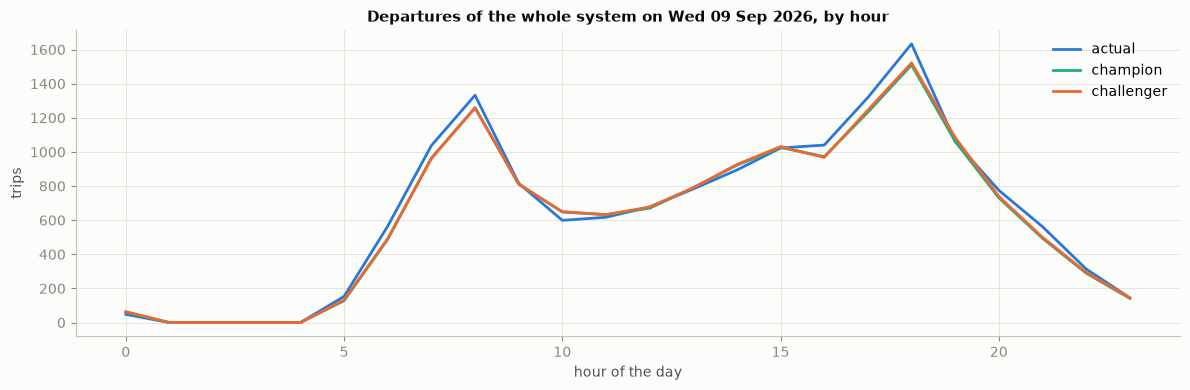

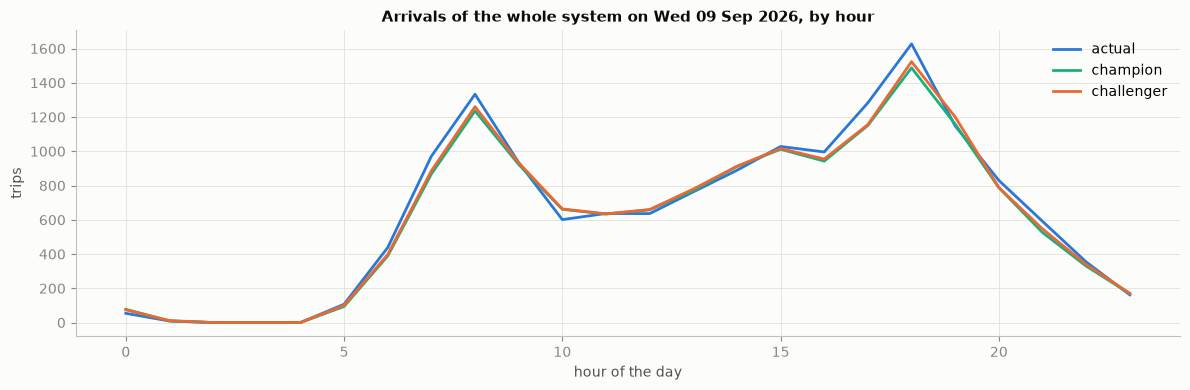

In [11]:
for target in TARGETS:
    by_hour = scored.groupby(scored[TIME].dt.hour)[
        [target, *(f"{target}_{a}" for a in ALIASES)]
    ].sum()
    by_hour.columns = ["actual", *ALIASES]
    plots.plot_lines(
        by_hour,
        f"{target.capitalize()} of the whole system on {NIGHT:%a %d %b %Y}, by hour",
        "trips",
        "hour of the day",
    )

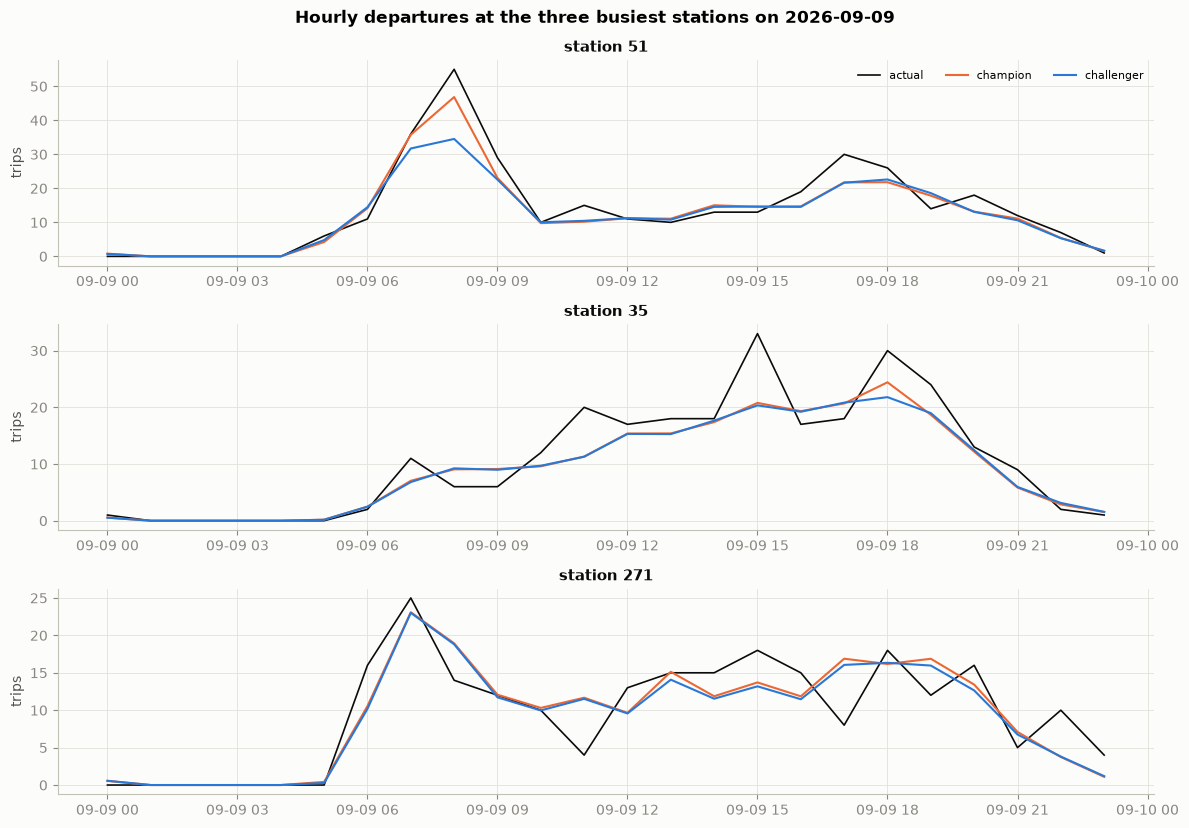

In [12]:
busiest = scored.groupby(STATION)["departures"].sum().nlargest(3).index
panels = {
    f"station {s}": scored[scored[STATION] == s]
    .set_index(TIME)[["departures", *(f"departures_{a}" for a in ALIASES)]]
    .set_axis(["actual", *ALIASES], axis=1)
    for s in busiest
}
plots.plot_station_forecasts(
    panels, f"Hourly departures at the three busiest stations on {NIGHT:%Y-%m-%d}", "trips"
);

**Result → action.**
- **Coverage.** The replayed forecast for Wednesday 9 September 2026 covers 467 stations × 24 h, built only from the history before that day. 15 stations of the table had no trip in the 28 days before, so they got no forecast; they are new or reopened stations, which the operations team plans by hand.
- **Accuracy.** On the champion's departures, the hourly WAPE is 0.541, the peak-hour WAPE 0.462 and the MAE 0.745. The daily WAPE of the station totals is 0.143: the daily total of a station, which is what the rebalancing plan uses, is off by 14%. Arrivals do slightly better (0.511, 0.416 and 0.137). This regular weekday scores better than the mean of the backtest (0.520 at peak hours).
- **The system as a whole.** The forecast follows the morning (08:00) and evening (18:00) peaks, but falls 5-7% short of them: about 1,520 against 1,640 departures at 18:00. Over the day, it forecasts 14,833 departures against 15,393 real ones (-3.6%).
- **The busiest stations.** The champion catches the 08:00 peak of station 51 better than the challenger (47 against 35, for 55 real).
- **Champion against challenger.** They are within 0.004 in every metric, as in the backtest.

→ The model the Registry serves reproduces the accuracy of the backtest on a replayed night, so the chain Registry → `predict` → forecast works end to end. Since the forecast falls short at the peaks, the team should keep a margin of bikes at the busiest stations.

## 5. The decision: which stations will empty or fill

The forecast serves the rebalancing plan: a station whose daily net flow (arrivals − departures) exceeds half its capacity will run out of bikes (negative) or of docks (positive) unless the team moves bikes. That is the decision metric of `2.01`, scored here for one day: how many of the station-days the forecast flags really were high-imbalance (precision), and how many of those it caught (recall).

In [13]:
decision = pd.DataFrame(
    {
        alias: imbalance_scores(scored, scored[f"departures_{alias}"], scored[f"arrivals_{alias}"])
        for alias in ALIASES
    }
).T
decision

,imbalance_days,flagged_days,imbalance_precision,imbalance_recall
champion,80.0,44.0,0.863636,0.4750
challenger,80.0,47.0,0.787234,0.4625


In [14]:
daily = scored.groupby(STATION).agg(
    capacity=("capacity", "first"),
    actual=("arrivals", "sum"),
    actual_departures=("departures", "sum"),
    forecast=(f"arrivals_{CHAMPION}", "sum"),
    forecast_departures=(f"departures_{CHAMPION}", "sum"),
)
daily = pd.DataFrame(
    {
        "capacity": daily["capacity"],
        "forecast net flow": daily["forecast"] - daily["forecast_departures"],
        "actual net flow": daily["actual"] - daily["actual_departures"],
    }
)
threshold = IMBALANCE_SHARE * daily["capacity"]
daily["flagged"] = daily["forecast net flow"].abs() > threshold
daily["high imbalance"] = daily["actual net flow"].abs() > threshold
order = (daily["forecast net flow"].abs() / daily["capacity"]).sort_values(ascending=False).index
daily.loc[order].head(TOP_STATIONS).round(1)

,capacity,forecast net flow,actual net flow,flagged,high imbalance
station_id,,,,,
194,19.0,-96.5,-83,True,True
35,15.0,39.8,49,True,True
34,15.0,39.5,38,True,True
260,15.0,29.0,11,True,True
341,19.0,26.8,29,True,True
384,23.0,27.3,30,True,True
6,11.0,12.8,6,True,True
42,19.0,21.7,34,True,True
197,15.0,-15.4,-13,True,True


**Result → action.** That day, 80 stations had a net flow beyond half their capacity.
- The champion flagged 44 of them, with a **precision of 0.86** (38 correct) and a **recall of 0.48** (38 of the 80). The challenger reached 0.79 and 0.46.
- The ten stations with the largest forecast imbalance relative to their capacity all really were high-imbalance stations.
- Station 194 was forecast at -96.5 and lost 83 bikes, against a capacity of 19: it needs to be refilled several times a day.

→ The list sorted by |forecast net flow| / capacity is the action list for the night: plan the routes from the top. Since the forecast misses about half of the imbalanced stations, the list should go beyond the 50% threshold: either the top N stations by that ratio, or a lower threshold, as `2.04` suggests.

## 6. The forecast of the next day

`predict_tracked()` is the nightly job: the 24 hours after the last hour of the feature table (1 October 2026), written to `data/processed/mibici/predictions/` and logged as a `predict-<start>` run with the model versions, the input digests and the forecast file as a dataset.

In [15]:
nightly = predict_tracked()
run = mlflow.get_run(nightly.run_id)
print(f"{nightly.path.relative_to(nightly.path.parents[4])}: {len(nightly.predictions):,} rows")
print(f"MLflow run {run.info.run_name} ({nightly.run_id})")
pd.Series(run.data.params).to_frame("param")

2026-11-07 16:20:47.497 | SUCCESS  | team2_mlops2026.modeling.predict:predict:132 - Forecast of 11,232 station-hours (468 stations) from 2026-10-01 00:00:00 with mibici-departures v1, mibici-arrivals v1
🏃 View run predict-2026-10-01-00h at: http://127.0.0.1:5001/#/experiments/1/runs/10845f69264a4d29a08bb2a7b9e25f4b
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
data/processed/mibici/predictions/forecast_20261001_00h.parquet: 11,232 rows
MLflow run predict-2026-10-01-00h (10845f69264a4d29a08bb2a7b9e25f4b)


,param
start,2026-10-01 00:00:00
hours,24
alias,champion
departures_model,mibici-departures/1
arrivals_model,mibici-arrivals/1
departures_model_run_id,0524ecdd8541472a9f16070b7e3412cf
arrivals_model_run_id,cd78b63838fb491ab138e321cfa76031


In [16]:
next_day = nightly.predictions.groupby(STATION)[[*TARGETS, NET_FLOW]].sum()
pd.concat(
    {
        "will empty": next_day.nsmallest(5, NET_FLOW),
        "will fill": next_day.nlargest(5, NET_FLOW),
    }
).round(1)

departures  arrivals  net_flow
           station_id                                
will empty 194              110.9      42.1     -68.8
           288               86.8      61.7     -25.2
           11               213.0     197.1     -15.9
           197               52.0      38.5     -13.5
           199               65.0      52.0     -13.0
will fill  51               319.6     362.4      42.8
           35               263.7     297.4      33.7
           34               147.0     177.4      30.4
           384               55.2      83.8      28.7
           260              147.8     167.9      20.1

**Result → action.** `predict_tracked()` wrote `forecast_20261001_00h.parquet`: 11,232 rows, 468 stations × 24 h of Thursday 1 October 2026 (the issue expected about 11.5 thousand). The `predict-2026-10-01-00h` run records the versions (`mibici-departures/1` and `mibici-arrivals/1`), their run ids and the input digests.
- **Totals.** The forecast is 18,090 departures and 18,075 arrivals. That is in line with the last weekdays of September (18.7-20.8 thousand) and slightly below them, as the backtest showed for the record month.
- **Stations past half their capacity.** 45 of them: 15 will empty (194 at -69, 288, 11, 197, 199) and 30 will fill (51 at +43, 35, 34, 384, 260).

Stations 194, 197, 35, 34, 384 and 260 also topped the simulated night. → This is the list the operations team would get on the night of 30 September. Since the same stations repeat, their imbalance is structural: a fixed rebalancing route or more docks there may pay off more than a daily decision.

## Findings and next steps

1. **Model Registry.** `mibici-departures` and `mibici-arrivals` have v1 (`lgbm_tweedie`, `champion`) and v2 (`hgb_poisson`, `challenger`). Each version is linked to its tune run, with a description and tags: training window, 8.6 million training rows, test-split and backtest metrics, success criterion (passed, 15.4% and 15.1% below the best baseline), input digests and git commit.
2. **Lineage verified.** The features digest of every version is the digest of the current feature table, so the registered models were trained on the data in `data/processed`.
3. **Replayed night (9 September 2026).** Peak-hour WAPE of 0.46 for departures and 0.42 for arrivals, daily WAPE of 0.14, and the system total 3.6% low. The champion flagged the high-imbalance stations with a precision of 0.86 and a recall of 0.48. The ten stations it ranked highest were all correct.
4. **Batch forecast.** `make predict` forecasts 11,232 station-hours (468 stations) of 1 October 2026 in about 10 seconds and logs the run. 45 stations will empty or fill beyond half their capacity, and several repeat every day.

Next steps:
- Run `make predict` every night after the data update, on a machine that does not sleep, such as a VM or a cloud server.
- Retrain monthly with `make train tune evaluate register`. The champion alias moves only if the new model passes the success criterion in the backtest, and the previous version stays in the Registry for a rollback.
- Add the stations without a trip in the last 28 days to the operations list by hand, and extend the action list beyond the 50% threshold to raise the recall.